# TuniShop — Data mining 02. Clustering des clients

**Auteure :** Sarra Abdeljaouad · **Phase :** data mining · **Source :** TuniShop_DWH (vues `bi`), via les tables de `05_Data/features` construites par `01_EDA/01_EDA_Global`

## Objectif

La segmentation RFM repose sur des **règles choisies à l'avance**. Le clustering fait l'inverse : il laisse un algorithme (**k-means**) regrouper les clients qui se ressemblent sur **plusieurs comportements à la fois**, sans règle imposée. On vérifie ensuite :
1. si les groupes trouvés sont **nets** (silhouette) et **interprétables** ;
2. ce qu'ils apportent **en plus du RFM** ;
3. s'ils sont **stables en 2025** et utiles pour le churn.

**Produit pour la suite :** la variable `cluster` (`05_Data/features/clusters_clients.parquet`) et le modèle (`06_Exports/Modeles/clustering_kmeans.joblib`).

**Plan :** 1. Données · 2. Variables · 3. Choix du nombre de groupes · 4. Profils des groupes · 5. Comparaison avec le RFM · 6. Groupes et churn (stabilité 2025) · 7. Visualisation · 8. Sauvegarde · 9. Synthèse

## 0. Préparation

In [1]:
# --- Bibliothèques
import sys
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- Module commun du projet (dossier 00_Commun)
sys.path.insert(0, "../00_Commun")
from tunishop_analytics import config as cfg, chargement, features, temporal_split, publication

warnings.filterwarnings("ignore", category=FutureWarning)
cfg.appliquer_style()
sql = chargement.requete                       # sql("SELECT ...") -> exécuté par SQL Server

def montrer(nom):
    """Enregistre la figure en cours dans 06_Exports/Figures/<nom>.png, puis l'affiche."""
    cfg.sauver_figure(plt.gcf(), nom)
    plt.show()

# --- Paramètre : True = reconstruire la table depuis les vues du DWH avant l'analyse
#     (utile si le DWH a été rechargé depuis la dernière exécution de 01_EDA_Global)
RECONSTRUIRE = False

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
import joblib

## 1. Données

La table `clients` (`05_Data/features/clients.parquet`) a été construite par `01_EDA_Global` à partir des vues `bi` du DWH. Avec `RECONSTRUIRE = True`, on la reconstruit ici directement depuis le DWH. Dans les deux cas, une requête **🔗 SQL direct** vérifie ensuite que la table correspond toujours au DWH.

In [2]:
chargement.ouvrir_connexion()
if RECONSTRUIRE:
    vues, p = chargement.charger_donnees(source="dwh")
    features.sauvegarder(features.table_clients(p), "clients")
clients = features.lire("clients")
print(f"clients : {len(clients):,} lignes x {clients.shape[1]} colonnes".replace(",", " "))

Connecté à TuniShop_DWH sur localhost (pilote : ODBC Driver 17 for SQL Server)
clients : 43 488 lignes x 28 colonnes


In [3]:
# 🔗 Contrôle SQL direct : nombre de clients actifs à chaque date d'observation, recalculé dans SQL Server
cle = lambda d: int(pd.Timestamp(d).strftime("%Y%m%d"))
lignes = []
for d in sorted(clients["date_observation"].unique()):
    debut = pd.Timestamp(d) - pd.Timedelta(days=temporal_split.FENETRE_ACTIVITE_J)          # même règle que features : dernière commande >= date - 365 j
    n_sql = chargement.valeur("""
        SELECT COUNT(DISTINCT c.client_sk)
        FROM bi.v_fact_commandes c
        JOIN bi.v_dim_statut_commande s ON s.statut_commande_sk = c.statut_commande_sk
        WHERE c.client_sk > 0 AND s.statut_commande <> 'paiement_echoue'
          AND c.date_commande_sk BETWEEN ? AND ?""", [cle(debut), cle(d)])
    lignes.append({"date_observation": pd.Timestamp(d).date(), "clients actifs (SQL)": int(n_sql),
                   "photos dans la table": int((clients["date_observation"] == d).sum())})
controle = pd.DataFrame(lignes)
controle["statut"] = np.where(controle["clients actifs (SQL)"] == controle["photos dans la table"], "OK", "ÉCART")
controle

,date_observation,clients actifs (SQL),photos dans la table,statut
0,2023-06-30,2545,2545,OK
1,2023-09-30,3308,3308,OK
2,2023-12-31,4014,4014,OK
3,2024-03-31,4374,4374,OK
4,2024-06-30,4724,4724,OK
5,2024-09-30,5109,5109,OK
6,2025-03-31,6214,6214,OK
7,2025-06-30,6332,6332,OK
8,2025-09-30,6868,6868,OK


> **Lecture.** Pour les **9 dates d'observation**, le nombre de clients actifs recalculé par SQL Server est identique au nombre de photos de la table `clients` : le clustering travaille sur les données du DWH.

## 2. Les variables du clustering

On décrit chaque client par 8 comportements. On utilise **une seule photo par client** : celle du **30/09/2024**, la dernière date d'apprentissage (sinon un même client compterait plusieurs fois).

| Variable | Pourquoi | Transformation |
|---|---|---|
| récence, fréquence, montant, panier moyen | valeur et activité (comme le RFM) | **logarithme** : distributions très asymétriques (EDA, valeurs extrêmes) |
| part des commandes sur mobile, part avec coupon | habitudes d'achat | aucune (déjà entre 0 et 1) |
| nombre de catégories achetées | diversité | aucune |
| part des livraisons en retard | expérience vécue | vide → 0 (pas encore de livraison reçue) |

Puis toutes les variables sont **standardisées** (moyenne 0, écart-type 1) : sinon le montant, qui se compte en centaines de dinars, écraserait les parts, qui sont entre 0 et 1.

In [4]:
# Les 8 variables sont définies dans le module commun (features.variables_clustering) :
# le scoring du jour (03_Machine_Learning/08_Scoring_Actuel) les recalcule exactement de la même façon.
VARIABLES = features.VARIABLES_CLUSTERING
preparer_x = features.variables_clustering

DATE_REF = temporal_split.DATES_OBS_APPRENTISSAGE[-1]               # 30/09/2024
ref = clients[clients["date_observation"] == DATE_REF].copy()
X_ref = preparer_x(ref)
echelle = StandardScaler().fit(X_ref)                                # moyenne et écart-type appris sur l'apprentissage
Z_ref = echelle.transform(X_ref)
print(f"{len(ref):,} clients au {DATE_REF.date()} ; {len(VARIABLES)} variables".replace(",", " "))
X_ref.describe().T.round(2)

5 109 clients au 2024-09-30 ; 8 variables


,count,mean,std,min,25%,50%,75%,max
log_recence,5 109.000,4.170,1.290,0.000,3.300,4.330,5.260,5.900
log_frequence,5 109.000,1.530,0.720,0.690,0.690,1.390,2.080,3.970
log_montant,5 109.000,5.960,1.850,0.000,5.000,6.130,7.220,9.870
log_panier,5 109.000,5.050,0.900,2.560,4.480,5.020,5.590,8.570
part_mobile,5 109.000,0.370,0.320,0.000,0.000,0.330,0.500,1.000
part_coupon,5 109.000,0.140,0.280,0.000,0.000,0.000,0.140,1.000
nb_categories,5 109.000,4.130,2.400,1.000,2.000,4.000,6.000,10.000
part_retard,5 109.000,0.110,0.220,0.000,0.000,0.000,0.140,1.000


## 3. Combien de groupes ?

Deux indicateurs, calculés pour 2 à 8 groupes :
- l'**inertie** (dispersion à l'intérieur des groupes) : elle baisse toujours ; on cherche le « coude » où elle baisse moins vite ;
- la **silhouette** (de -1 à 1) : plus elle est haute, plus les groupes sont nets et séparés. Au-dessus de 0,5 la structure est forte ; vers 0,2 elle est faible.

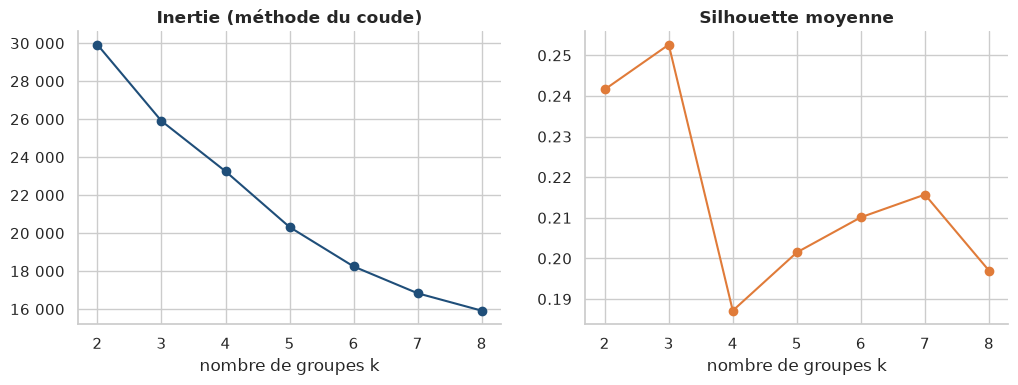

Publication : connecté à TuniShop_ANALYTICS sur localhost
  ✔ ana.dm02_choix_k                                  7 lignes


,inertie,silhouette
k,,
2,29 921.879,0.242
3,25 903.989,0.253
4,23 253.563,0.187
5,20 318.287,0.201
6,18 243.094,0.210
7,16 831.596,0.216
8,15 915.515,0.197


In [5]:
essais = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z_ref)
    essais.append({"k": k, "inertie": km.inertia_,
                   "silhouette": silhouette_score(Z_ref, km.labels_, sample_size=4000, random_state=0)})
essais = pd.DataFrame(essais).set_index("k")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(essais.index, essais["inertie"], marker="o", color=cfg.BLEU); axes[0].set_title("Inertie (méthode du coude)")
cfg.format_milliers(axes[0])
axes[1].plot(essais.index, essais["silhouette"], marker="o", color=cfg.ORANGE); axes[1].set_title("Silhouette moyenne")
for ax in axes: ax.set_xlabel("nombre de groupes k")
montrer("DM02_1_choix_k")
cfg.exporter_table(essais, "DM02_choix_k")
essais.round(3)

> **Lecture.** La **silhouette reste faible** (0,19 à 0,25) : les clients forment un continuum plutôt que des groupes très séparés, ce qui est courant pour des comportements d'achat. L'inertie ne montre pas de coude net. La meilleure silhouette est à 3 groupes (0,253), mais avec **4 groupes** l'algorithme isole un comportement que le RFM ne voit pas : les **chasseurs de coupons**. L'écart de silhouette est faible (0,19 contre 0,25), et l'interprétation est plus riche : on retient **k = 4**.

In [6]:
K = 4                                                     # choix expliqué dans la lecture ci-dessus
modele = KMeans(n_clusters=K, n_init=10, random_state=42).fit(Z_ref)
ref["cluster_num"] = modele.labels_

# Nommer les groupes par des règles sur leurs médianes (les numéros de k-means n'ont pas de sens)
med = ref.groupby("cluster_num").agg(frequence=("frequence", "median"), part_coupon=("part_coupon", "mean"),
                                     montant=("montant_reconnu_ttc", "median"))
noms = {}
noms[med["frequence"].idxmax()] = "Grands clients"
noms[med.drop(list(noms))["part_coupon"].idxmax()] = "Chasseurs de coupons"
reste = med.drop(list(noms))
noms[reste["frequence"].idxmax() if reste["frequence"].nunique() > 1 else reste["montant"].idxmax()] = "Réguliers"
noms[med.drop(list(noms)).index[0]] = "Acheteurs uniques"
NOMS = noms
ref["cluster"] = ref["cluster_num"].map(NOMS)
NOMS

{np.int32(0): 'Grands clients',
 np.int32(3): 'Chasseurs de coupons',
 np.int32(1): 'Réguliers',
 np.int32(2): 'Acheteurs uniques'}

## 4. Profils des groupes

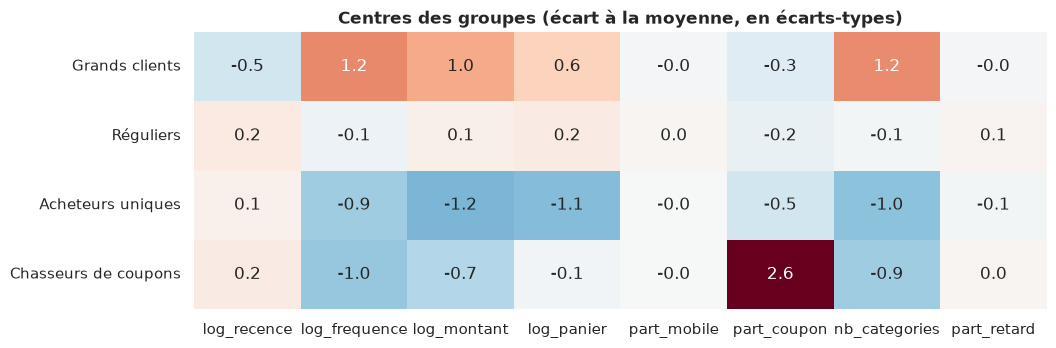

  ✔ ana.dm02_profil_clusters                          4 lignes


,clients,recence_mediane_j,frequence_mediane,montant_median_ttc,panier_median_ttc,part_mobile,part_coupon,categories_medianes,part_retard,professionnels,part_clients
cluster,,,,,,,,,,,
Acheteurs uniques,1129,103.000,1.000,60.600,54.300,0.362,0.007,1.000,0.106,0.004,0.221
Chasseurs de coupons,535,114.000,1.000,139.920,123.910,0.364,0.870,2.000,0.137,0.000,0.105
Grands clients,1488,31.000,10.000,2 269.950,239.554,0.355,0.060,7.000,0.101,0.075,0.291
Réguliers,1957,120.000,3.000,487.900,168.301,0.385,0.090,4.000,0.127,0.016,0.383


In [7]:
profil = ref.groupby("cluster").agg(
    clients=("client_sk", "size"), recence_mediane_j=("recence_j", "median"), frequence_mediane=("frequence", "median"),
    montant_median_ttc=("montant_reconnu_ttc", "median"), panier_median_ttc=("panier_moyen_ttc", "median"),
    part_mobile=("part_mobile", "mean"), part_coupon=("part_coupon", "mean"), categories_medianes=("nb_categories", "median"),
    part_retard=("part_livraisons_retard", "mean"), professionnels=("type_client", lambda s: (s == "professionnel").mean()))
profil["part_clients"] = profil["clients"] / profil["clients"].sum()

# Carte des centres des groupes en unités standardisées : > 0 = au-dessus de la moyenne des clients
centres = pd.DataFrame(modele.cluster_centers_, columns=VARIABLES).rename(index=NOMS)
fig, ax = plt.subplots(figsize=(11, 3.6))
sns.heatmap(centres, annot=True, fmt=".1f", cmap="RdBu_r", center=0, cbar=False, ax=ax)
ax.set_title("Centres des groupes (écart à la moyenne, en écarts-types)")
montrer("DM02_2_centres")
cfg.exporter_table(profil, "DM02_profil_clusters")
profil

> **Lecture.** Les 4 groupes ont des profils nets : **Grands clients** (29 %, 10 commandes, 2 270 DT, 7 catégories, 7,5 % de professionnels), **Réguliers** (38 %, 3 commandes, 488 DT), **Acheteurs uniques** (22 %, 1 commande, 61 DT) et **Chasseurs de coupons** (10 %, 87 % de leurs commandes avec coupon, 140 DT). La part sur mobile et la part de livraisons en retard ne distinguent aucun groupe (centres proches de 0) : ces deux comportements sont répartis uniformément.

## 5. Comparaison avec la segmentation RFM

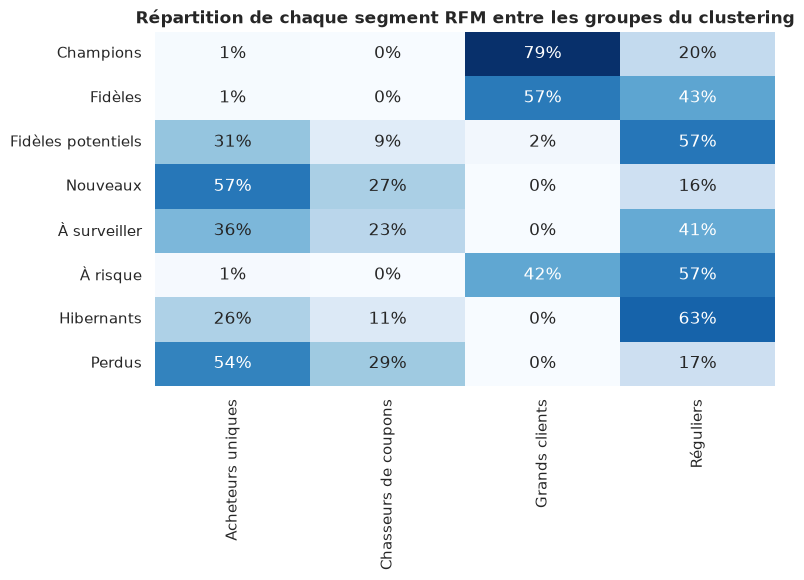

In [8]:
seg = features.lire("segments_rfm")[["client_sk", "date_observation", "segment_rfm"]]
ref = ref.merge(seg, on=["client_sk", "date_observation"], how="left")
croise = pd.crosstab(ref["segment_rfm"], ref["cluster"], normalize="index").reindex(features.ORDRE_SEGMENTS)

fig, ax = plt.subplots(figsize=(8, 4.6))
sns.heatmap(croise, annot=True, fmt=".0%", cmap="Blues", cbar=False, ax=ax)
ax.set_title("Répartition de chaque segment RFM entre les groupes du clustering"); ax.set_xlabel(""); ax.set_ylabel("")
montrer("DM02_3_rfm_vs_clusters")

> **Lecture.** Les deux méthodes se recoupent : 79 % des Champions sont des Grands clients. Mais elles se complètent : le clustering **sépare les chasseurs de coupons** au sein des Nouveaux (27 %) et des Perdus (29 %), tandis que le RFM **distingue la récence** que le clustering mélange (les clients À risque sont répartis entre Grands clients et Réguliers).

## 6. Les groupes expliquent-ils le churn ? Sont-ils stables en 2025 ?

Le modèle (échelle + k-means) appris sur la photo du 30/09/2024 est **appliqué sans réapprentissage** à toutes les photos, y compris celles de 2025. Si les groupes gardent le même profil et des taux de churn proches, ils sont stables.

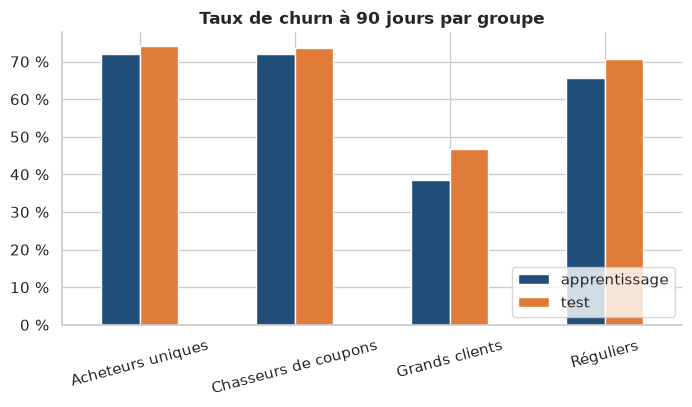

  ✔ ana.dm02_stabilite_clusters                       4 lignes


periode,apprentissage,test,part_apprentissage,part_test
cluster,,,,
Acheteurs uniques,0.721,0.741,0.257,0.216
Chasseurs de coupons,0.720,0.735,0.119,0.110
Grands clients,0.385,0.468,0.233,0.310
Réguliers,0.656,0.706,0.391,0.363


In [9]:
tous = clients.copy()
tous["cluster"] = pd.Series(modele.predict(echelle.transform(preparer_x(tous))), index=tous.index).map(NOMS)

stab = tous.pivot_table(index="cluster", columns="periode", values="churn", aggfunc="mean")
stab["part_apprentissage"] = tous[tous["periode"] == "apprentissage"]["cluster"].value_counts(normalize=True)
stab["part_test"] = tous[tous["periode"] == "test"]["cluster"].value_counts(normalize=True)

fig, ax = plt.subplots(figsize=(8, 3.8))
stab[["apprentissage", "test"]].plot.bar(ax=ax, color=[cfg.BLEU, cfg.ORANGE], rot=15)
ax.set_title("Taux de churn à 90 jours par groupe"); cfg.format_pourcent(ax); ax.set_xlabel(""); ax.legend(title="", loc="lower right")
montrer("DM02_4_churn_clusters")
cfg.exporter_table(stab, "DM02_stabilite_clusters")
stab

> **Lecture.** Appliqué à 2025 sans réapprentissage, le modèle garde la même hiérarchie : les Grands clients ont le churn le plus bas (39 % puis 47 %), les trois autres groupes entre 66 % et 74 %. La part des Grands clients grandit en 2025 (23 % → 31 % des photos), car l'historique des clients s'allonge. Les écarts de churn sont **moins marqués qu'avec le RFM** (28 % à 88 %), parce que le clustering donne peu de poids à la récence. **Pour le ML :** `segment_rfm` sera la variable principale ; `cluster` apporte surtout l'information « chasseur de coupons ».

## 7. Visualisation en deux dimensions (ACP)

L'analyse en composantes principales (ACP) résume les 8 variables en 2 axes, pour dessiner les clients sur un plan. Ce n'est qu'une **projection** : des groupes qui se chevauchent ici peuvent être mieux séparés dans les 8 dimensions.

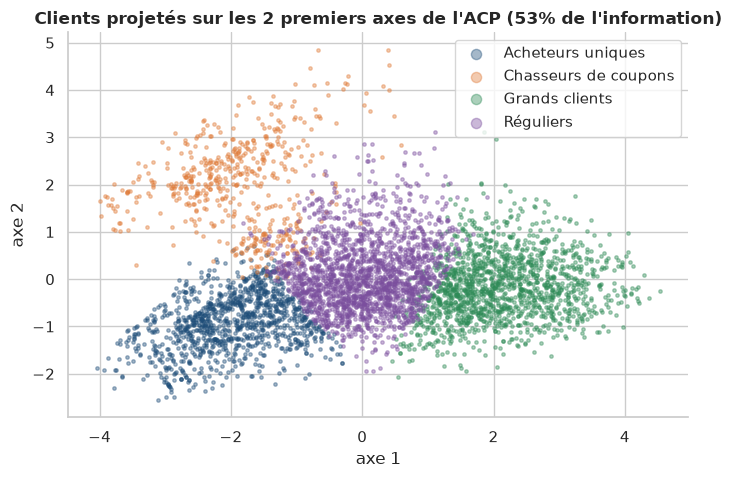

,axe 1,axe 2
log_recence,-0.160,0.320
log_frequence,0.520,-0.160
log_montant,0.520,0.170
log_panier,0.370,0.530
part_mobile,-0.020,0.010
part_coupon,-0.170,0.720
nb_categories,0.530,-0.040
part_retard,-0.010,0.180


In [10]:
acp = PCA(n_components=2, random_state=0).fit(Z_ref)
plan = acp.transform(Z_ref)
fig, ax = plt.subplots(figsize=(8, 5))
for i, (nom, g) in enumerate(ref.groupby("cluster")):
    idx = g.index.map(lambda j: ref.index.get_loc(j))
    ax.scatter(plan[idx, 0], plan[idx, 1], s=6, alpha=0.4, color=cfg.PALETTE[i], label=nom)
ax.set_title(f"Clients projetés sur les 2 premiers axes de l'ACP ({acp.explained_variance_ratio_.sum():.0%} de l'information)")
ax.set_xlabel("axe 1"); ax.set_ylabel("axe 2"); ax.legend(markerscale=3)
montrer("DM02_5_acp")
pd.DataFrame(acp.components_.T, index=VARIABLES, columns=["axe 1", "axe 2"]).round(2)

## 8. Sauvegarde du modèle et de la variable « cluster »

In [11]:
cfg.DOSSIER_MODELES.mkdir(parents=True, exist_ok=True)
joblib.dump({"echelle": echelle, "kmeans": modele, "noms": NOMS, "variables": VARIABLES, "date_reference": str(DATE_REF.date())},
            cfg.DOSSIER_MODELES / "clustering_kmeans.joblib")
features.sauvegarder(tous[["client_sk", "date_observation", "periode", "cluster"]], "clusters_clients")
print("Modèle enregistré : 06_Exports/Modeles/clustering_kmeans.joblib")

  clusters_clients         43 488 lignes x  4 colonnes -> clusters_clients.parquet


  ✔ ana.dm_clusters_clients                      43 488 lignes
Modèle enregistré : 06_Exports/Modeles/clustering_kmeans.joblib


## 9. Synthèse

> **Lecture.** Le clustering k-means confirme les grands profils du RFM et ajoute un **comportement de chasse aux coupons** (10 % des clients). La structure est faible (silhouette 0,19) : les groupes sont des repères utiles, pas des frontières nettes. Le modèle (échelle + k-means, appris sur l'apprentissage) est enregistré dans `06_Exports/Modeles/clustering_kmeans.joblib` et la variable `cluster` dans `05_Data/features/clusters_clients.parquet`.

In [12]:
chargement.fermer_connexion()

Connexion fermée.
